# Modeling and Simulation: Problem Sheet 6, exercise 1(d)

Problem sheet 6, exercise 1(d).

Series RLC circuit without a source.
State variables: capacitor voltage v and loop current i.

    dv/dt = i / C
    di/dt = -(v + R i) / L

solved with forward Euler, backward Euler and the trapezoidal method.

In [1]:
%matplotlib inline

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# ---------------- parameters ----------------
R = 50.0        # resistance in Ohm
L = 5.0         # inductance in H
C = 0.0001      # capacitance in F
V0 = 1.0        # initial capacitor voltage in V
I0 = 0.0        # initial inductor (loop) current in A
t_end = 1.0     # end time in s


def simulate(h):
    """Return t and (v, i) for the three methods with step size h."""
    t = np.arange(0, t_end + h / 2, h)
    N = len(t)

    # arrays for the three methods
    v_fe = np.zeros(N); i_fe = np.zeros(N)     # forward Euler
    v_be = np.zeros(N); i_be = np.zeros(N)     # backward Euler
    v_tr = np.zeros(N); i_tr = np.zeros(N)     # trapezoidal

    # initial conditions
    v_fe[0] = V0; i_fe[0] = I0
    v_be[0] = V0; i_be[0] = I0
    v_tr[0] = V0; i_tr[0] = I0

    # constants for the implicit methods (the 2x2 system is solved by hand)
    d_be = 1 + h * R / L + h**2 / (L * C)
    a_tr = h * R / (2 * L) + h**2 / (4 * L * C)

    for n in range(N - 1):
        # (i) forward Euler: slopes at the OLD time step
        v_fe[n + 1] = v_fe[n] + h * i_fe[n] / C
        i_fe[n + 1] = i_fe[n] - h * (v_fe[n] + R * i_fe[n]) / L

        # (ii) backward Euler: slopes at the NEW time step
        i_be[n + 1] = (i_be[n] - h * v_be[n] / L) / d_be
        v_be[n + 1] = v_be[n] + h * i_be[n + 1] / C

        # (iii) trapezoidal: average of the OLD and NEW slopes
        i_tr[n + 1] = ((1 - a_tr) * i_tr[n] - h * v_tr[n] / L) / (1 + a_tr)
        v_tr[n + 1] = v_tr[n] + h * (i_tr[n] + i_tr[n + 1]) / (2 * C)

    return t, (v_fe, i_fe), (v_be, i_be), (v_tr, i_tr)


def exact(t):
    """Analytical solution of the underdamped circuit (for verification)."""
    alpha = R / (2 * L)                       # damping rate in 1/s
    w0 = 1 / np.sqrt(L * C)                   # undamped angular frequency
    wd = np.sqrt(w0**2 - alpha**2)            # damped angular frequency
    B = (alpha * V0 + I0 / C) / wd
    v = np.exp(-alpha * t) * (V0 * np.cos(wd * t) + B * np.sin(wd * t))
    i = C * np.exp(-alpha * t) * ((wd * B - alpha * V0) * np.cos(wd * t)
                                  - (alpha * B + wd * V0) * np.sin(wd * t))
    return v, i

In [4]:
# ---------------- main run with h = 0.001 s ----------------
h = 0.001
t, fe, be, tr = simulate(h)
v_ex, i_ex = exact(t)

alpha = R / (2 * L)
w0 = 1 / np.sqrt(L * C)
print(f"alpha = {alpha} 1/s, omega0 = {w0:.3f} rad/s, "
      f"omega_d = {np.sqrt(w0**2 - alpha**2):.3f} rad/s -> underdamped")
print(f"period T_d = {2 * np.pi / np.sqrt(w0**2 - alpha**2):.4f} s\n")

print(f"h = {h} s: values at t = 1 s")
print(f"{'method':>16} {'v (V)':>11} {'i (mA)':>10}")
for name, (v, i) in (("forward Euler", fe), ("backward Euler", be),
                     ("trapezoidal", tr)):
    print(f"{name:>16} {v[-1]:>11.6f} {1000 * i[-1]:>10.5f}")
print(f"{'exact':>16} {v_ex[-1]:>11.6f} {1000 * i_ex[-1]:>10.5f}")

alpha = 5.0 1/s, omega0 = 44.721 rad/s, omega_d = 44.441 rad/s -> underdamped
period T_d = 0.1414 s

h = 0.001 s: values at t = 1 s
          method       v (V)     i (mA)
   forward Euler    0.015554   -0.04924
  backward Euler    0.002573   -0.00240
     trapezoidal    0.006409   -0.01327
           exact    0.006377   -0.01343


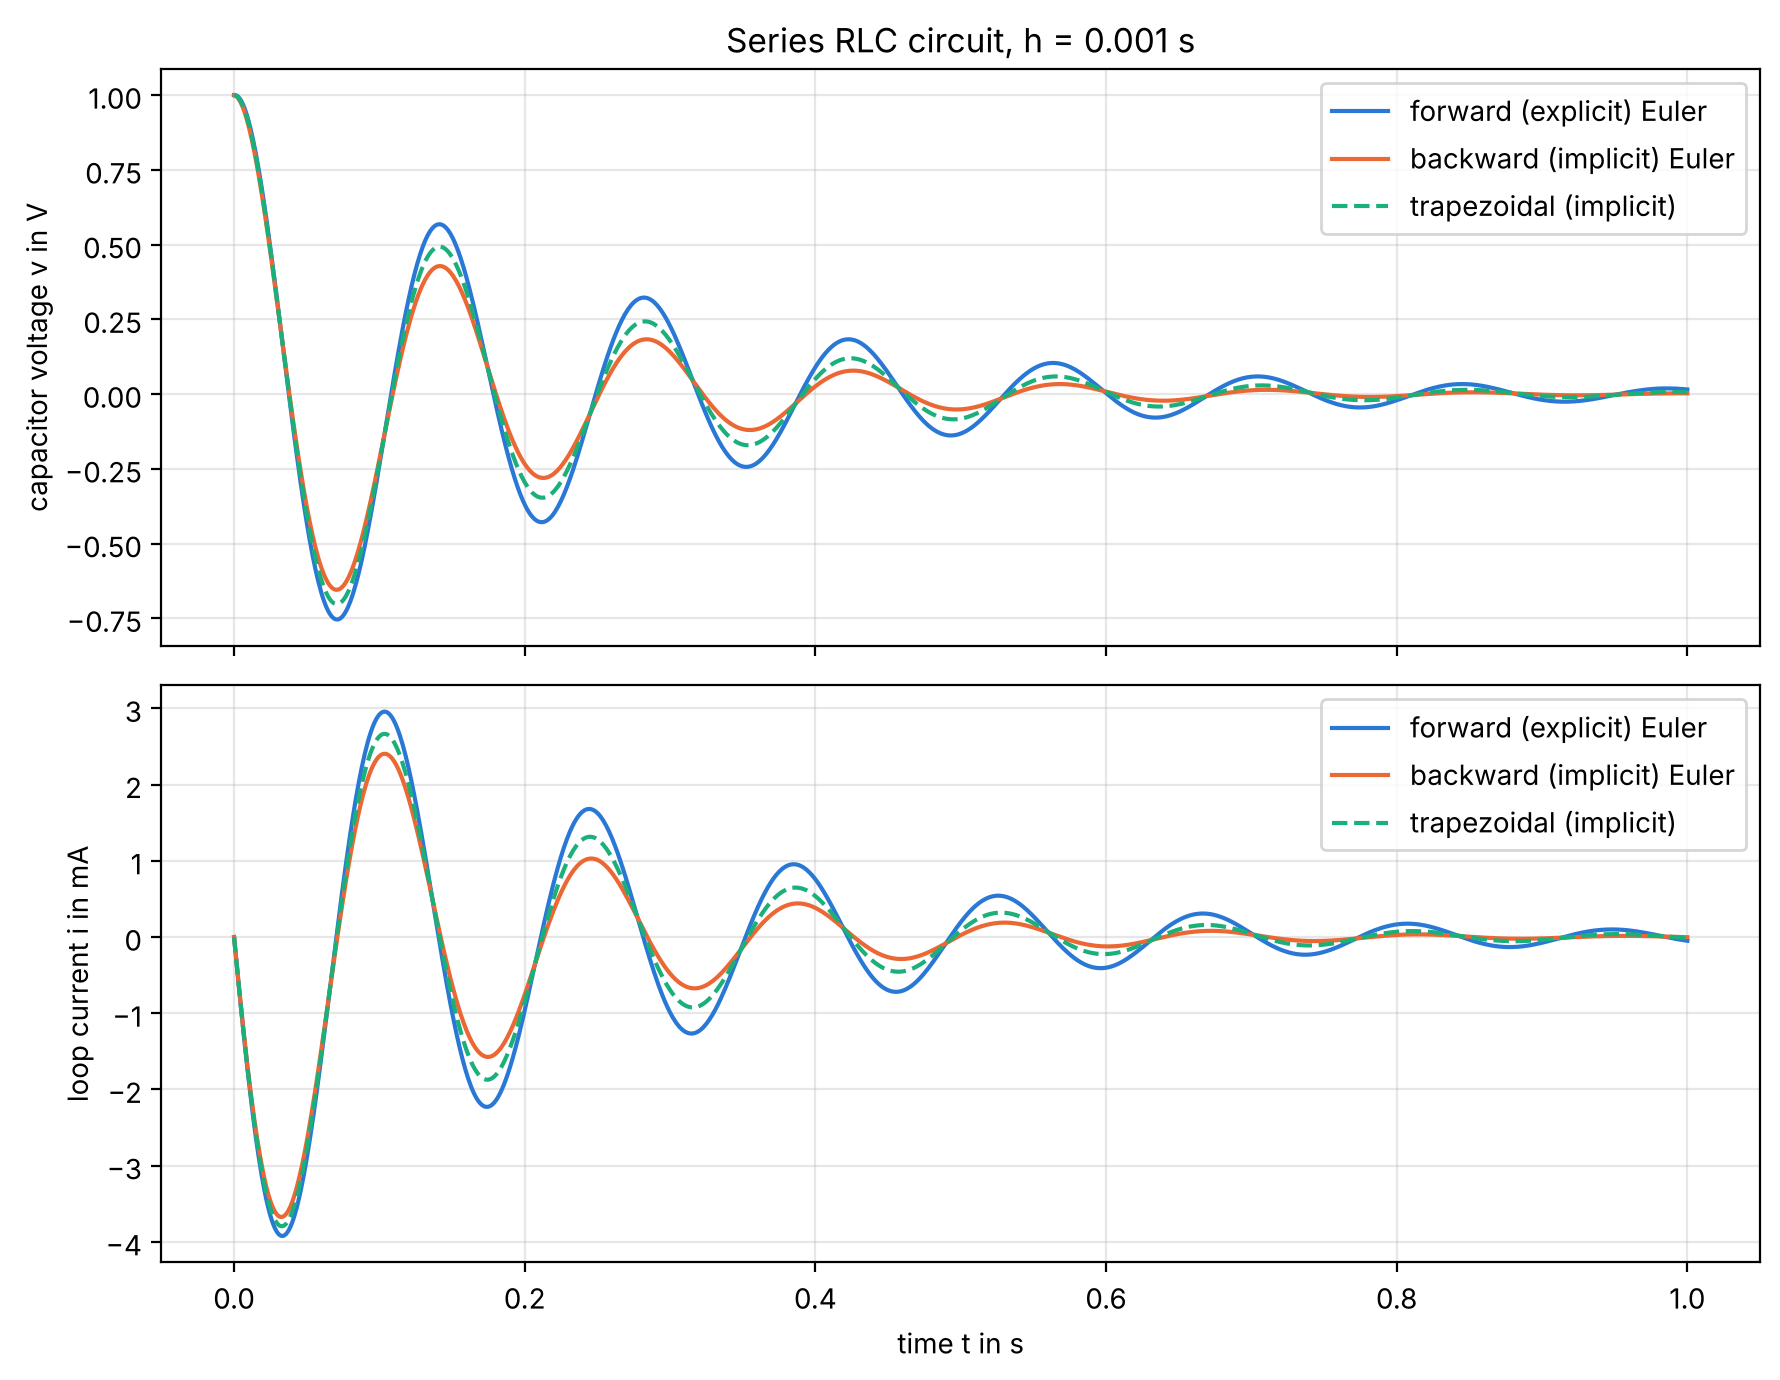

In [5]:
# ---------------- plot: two subplots, three methods each ----------------
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

ax1.plot(t, fe[0], color="#2a78d6", label="forward (explicit) Euler")
ax1.plot(t, be[0], color="#eb6834", label="backward (implicit) Euler")
ax1.plot(t, tr[0], color="#1baf7a", ls="--", label="trapezoidal (implicit)")
ax1.set_ylabel("capacitor voltage v in V")
ax1.set_title(f"Series RLC circuit, h = {h} s")
ax1.legend(loc="upper right")
ax1.grid(alpha=0.3)

ax2.plot(t, 1000 * fe[1], color="#2a78d6", label="forward (explicit) Euler")
ax2.plot(t, 1000 * be[1], color="#eb6834", label="backward (implicit) Euler")
ax2.plot(t, 1000 * tr[1], color="#1baf7a", ls="--", label="trapezoidal (implicit)")
ax2.set_xlabel("time t in s")
ax2.set_ylabel("loop current i in mA")
ax2.legend(loc="upper right")
ax2.grid(alpha=0.3)

fig.tight_layout()
fig.savefig("ps6_ex1d_plot_h0.001.png", dpi=200)
plt.show()


maximum error over 0 <= t <= 1 s compared with the exact solution
   h (s)  FE: max|v-v_ex|  BE: max|v-v_ex|  TR: max|v-v_ex|
    0.01        1.114e+02        3.793e-01        5.347e-02
   0.001        8.236e-02        6.671e-02        5.458e-04
  0.0001        7.474e-03        7.319e-03        5.459e-06
   forward Euler: E(1 s)/E(0) = 3.631e-04
  backward Euler: E(1 s)/E(0) = 6.907e-06
     trapezoidal: E(1 s)/E(0) = 4.987e-05
           exact: E(1 s)/E(0) = 4.968e-05


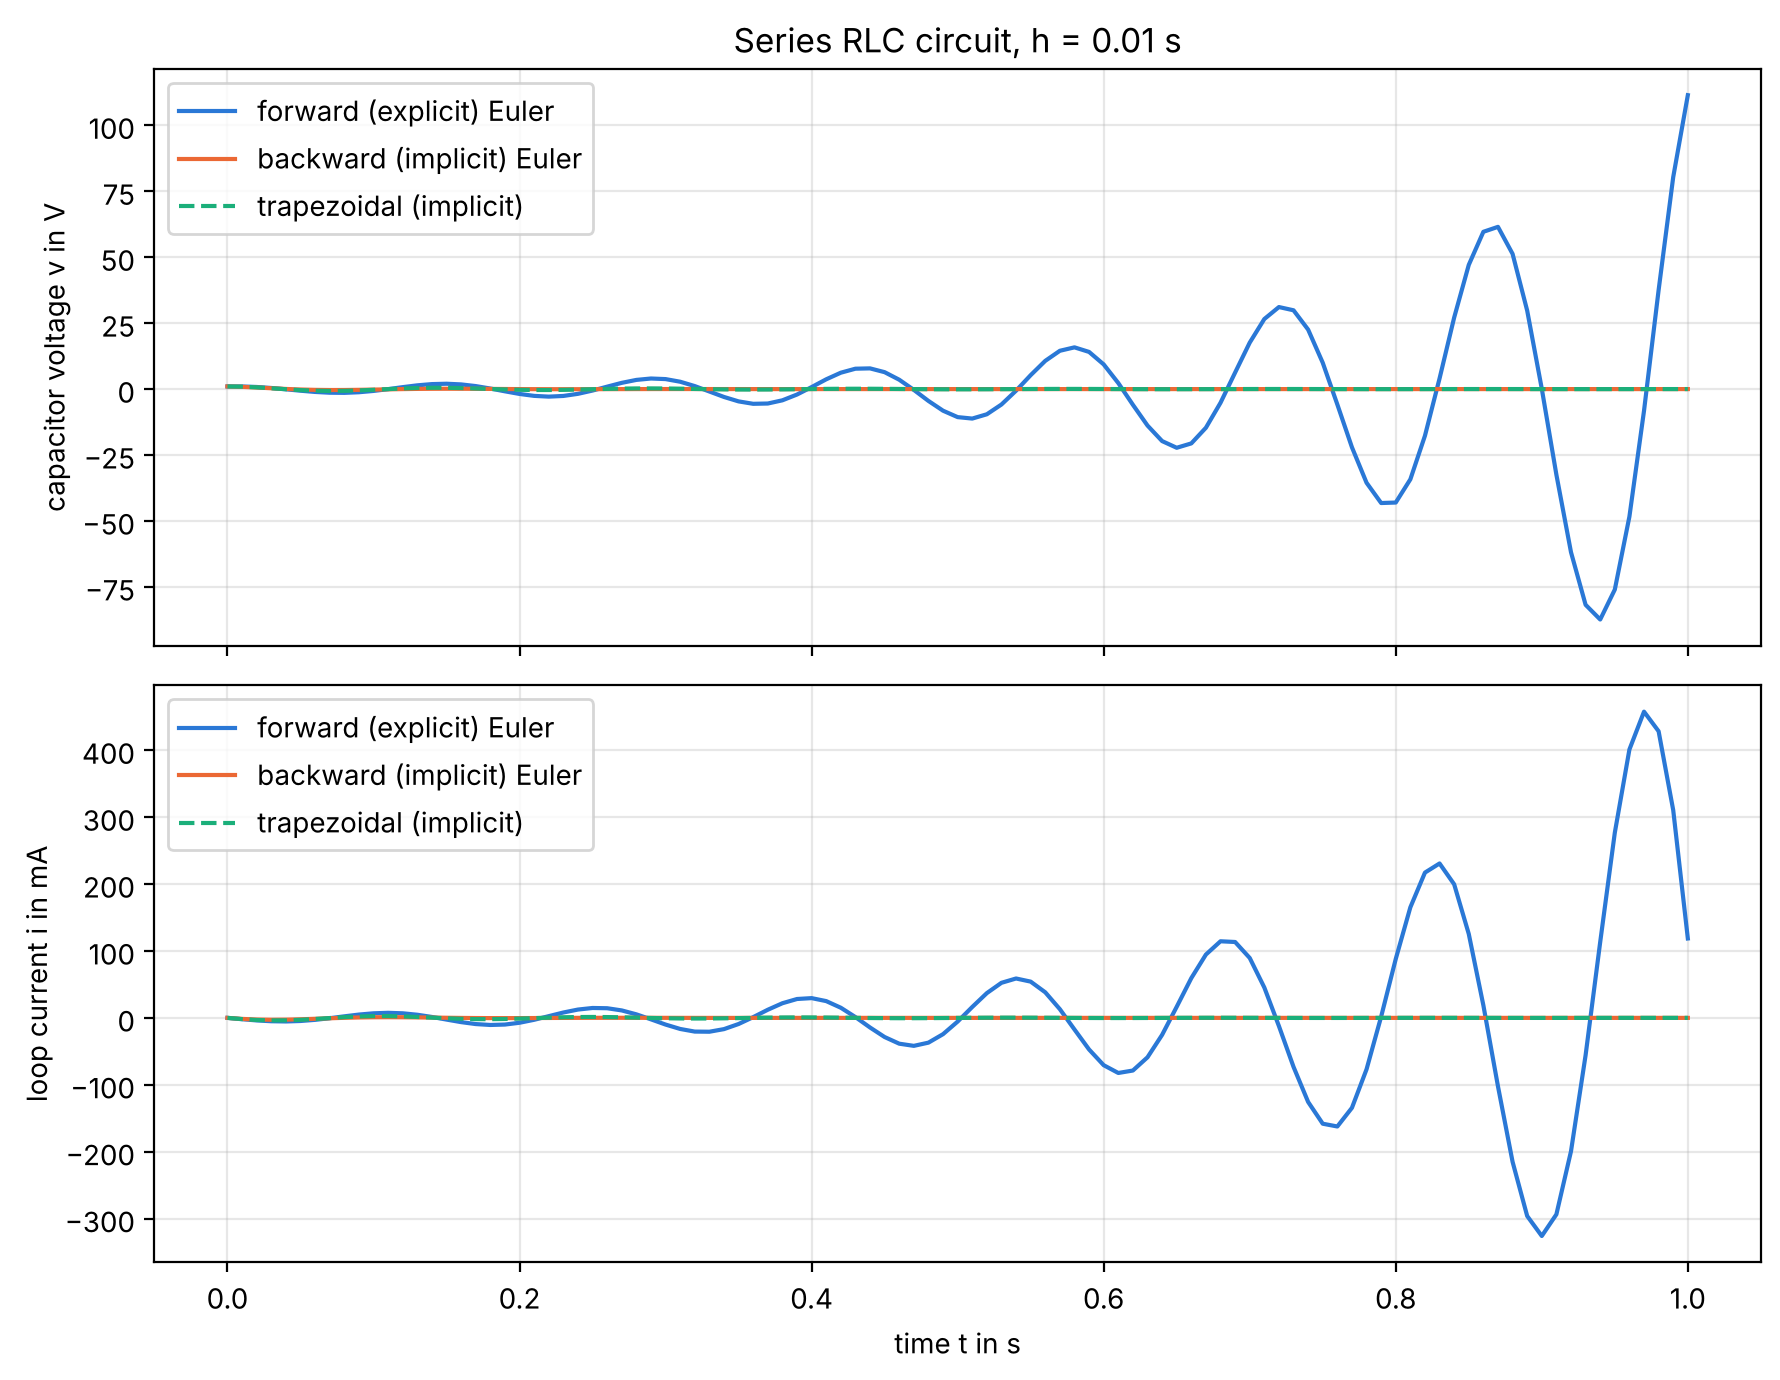

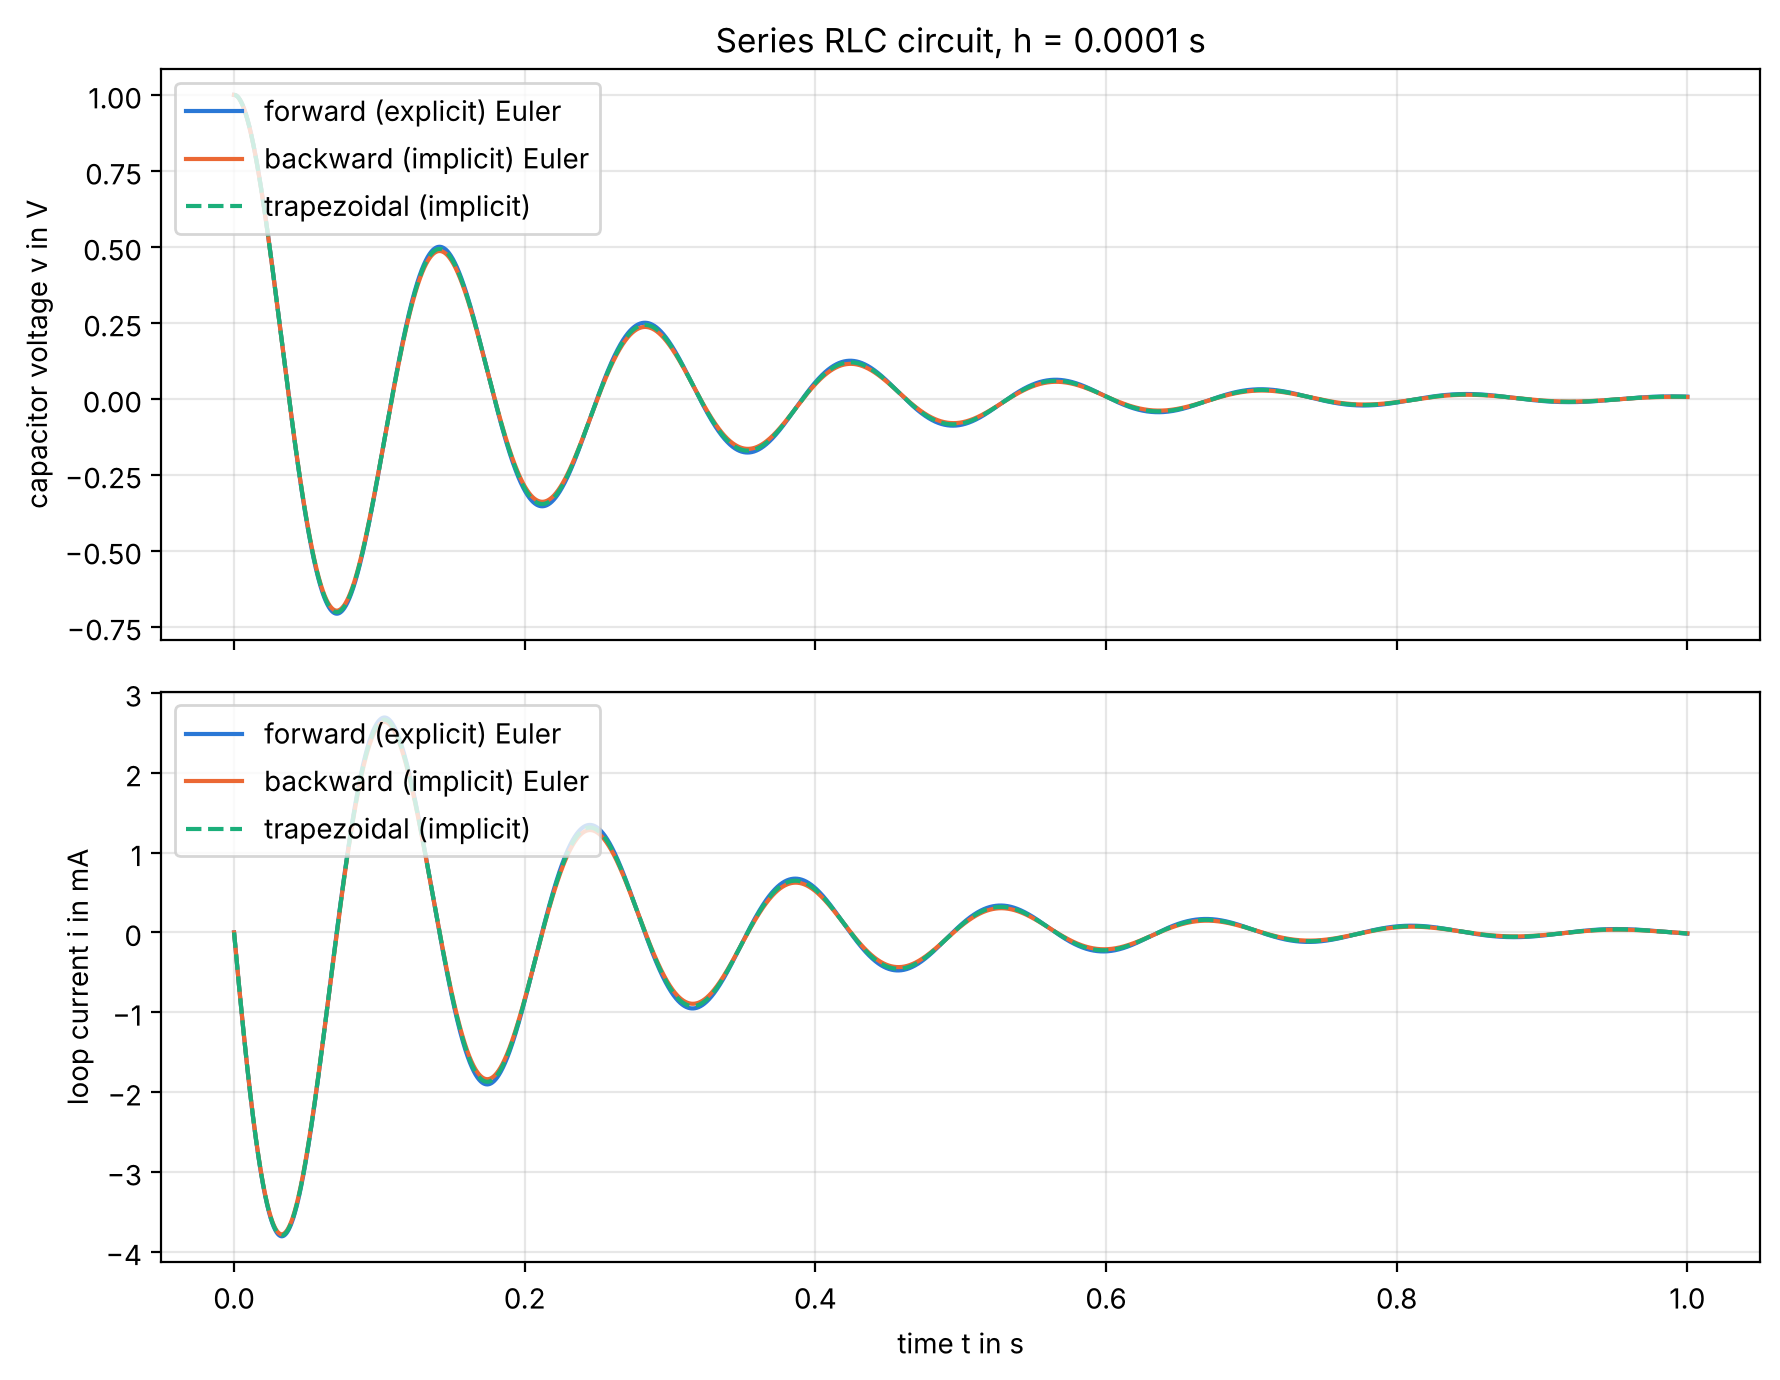

In [6]:
# ---------------- part (e): other step sizes ----------------
print("\nmaximum error over 0 <= t <= 1 s compared with the exact solution")
print(f"{'h (s)':>8} {'FE: max|v-v_ex|':>16} {'BE: max|v-v_ex|':>16} "
      f"{'TR: max|v-v_ex|':>16}")
for hh in (0.01, 0.001, 0.0001):
    tt, f1, b1, t1 = simulate(hh)
    ve, ie = exact(tt)
    errs = [np.max(np.abs(m[0] - ve)) for m in (f1, b1, t1)]
    print(f"{hh:>8} {errs[0]:>16.3e} {errs[1]:>16.3e} {errs[2]:>16.3e}")

# energy check E = C v^2 / 2 + L i^2 / 2 must never increase (dE/dt = -R i^2)
for name, (v, i) in (("forward Euler", fe), ("backward Euler", be),
                     ("trapezoidal", tr)):
    E = 0.5 * C * v**2 + 0.5 * L * i**2
    print(f"{name:>16}: E(1 s)/E(0) = {E[-1] / E[0]:.3e}")
E_ex = 0.5 * C * v_ex**2 + 0.5 * L * i_ex**2
print(f"{'exact':>16}: E(1 s)/E(0) = {E_ex[-1] / E_ex[0]:.3e}")

# the same plot for h = 0.01 s and h = 0.0001 s
for hh in (0.01, 0.0001):
    tt, f1, b1, t1 = simulate(hh)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
    for ax, k, scale, lab in ((ax1, 0, 1, "capacitor voltage v in V"),
                              (ax2, 1, 1000, "loop current i in mA")):
        ax.plot(tt, scale * f1[k], color="#2a78d6", label="forward (explicit) Euler")
        ax.plot(tt, scale * b1[k], color="#eb6834", label="backward (implicit) Euler")
        ax.plot(tt, scale * t1[k], color="#1baf7a", ls="--", label="trapezoidal (implicit)")
        ax.set_ylabel(lab)
        ax.legend(loc="upper left")
        ax.grid(alpha=0.3)
    ax1.set_title(f"Series RLC circuit, h = {hh} s")
    ax2.set_xlabel("time t in s")
    fig.tight_layout()
    fig.savefig(f"ps6_ex1d_plot_h{hh}.png", dpi=200)
    plt.show()